# Lab 1: Hệ Thống Thanh Bập Bênh Cân Bằng Bóng (Ball & Beam Control) với Q-Learning
- **Chạy cửa sổ mô phỏng trực tiếp (GUI)**: `python ball_and_beam_qlearning.py`
- **Trạng thái liên tục**: Vị trí bóng lăn trên thanh $x \in [-1.0, 1.0]\text{ m}$, vận tốc lăn $v$, và góc nghiêng của thanh $\theta \in [-15^\circ, +15^\circ]$.
- **Hành động**: `0 = Nghiêng thanh sang trái`, `1 = Giữ nguyên góc thanh`, `2 = Nghiêng thanh sang phải`.
- **Mục tiêu**: Nghiêng thanh để hãm phanh quả bóng đang lăn và đưa bóng về đứng yên tại tâm trục xoay ($x = 0.0\text{ m}$).


In [1]:
# Lab 1: Ball & Beam Balancing Control with Q-Learning - Interactive Physics Simulator (Tkinter GUI)
import math
import tkinter as tk
import numpy as np


# =====================================================================
# 1. BALL & BEAM PHYSICS ENVIRONMENT & Q-LEARNING AGENT
# =====================================================================
class BallAndBeamEnv:
    """
    Ball and Beam Balancing Control System (Classic Control & Robotics Benchmark).
    - A steel ball rolls on a pivoting beam of length 2.0 m (x in [-1.0, +1.0]).
    - Continuous State: (x, v, theta)
      * x in [-1.0, +1.0] m: Ball position from the center pivot (Target: x = 0.0)
      * v in [-1.2, +1.2] m/s: Ball rolling velocity along the beam
      * theta in [-0.24, +0.24] rad (+/- 13.7 deg): Beam tilt angle
    - Actions:
      * 0: Tilt Beam Left  (Drive tilt toward negative angle to push ball Left)
      * 1: Stabilize / Center Beam (Smoothly level the beam when near equilibrium)
      * 2: Tilt Beam Right (Drive tilt toward positive angle to push ball Right)
    - Goal: Prevent the ball from rolling off the edges (|x| > 1.0) and smoothly stabilize it at x = 0.
    """
    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)
        self.gravity = 9.81
        self.dt = 0.025
        self.max_x = 1.0
        self.max_v = 1.2
        self.max_theta = math.radians(14.0)
        self.theta_dot = 0.0
        self.num_actions = 3
        self.reset()

    def reset(self):
        # Start the ball rolling outward toward an edge so an untrained beam drops it quickly
        side = -1.0 if self.rng.random() < 0.5 else 1.0
        self.x = float(side * self.rng.uniform(0.40, 0.68))
        self.v = float(side * self.rng.uniform(0.28, 0.45))
        self.theta = float(side * self.rng.uniform(0.03, 0.08))
        self.theta_dot = 0.0
        return self.get_state()

    def get_state(self):
        return (self.x, self.v, self.theta)

    def step(self, action):
        # Smooth servo actuator dynamics (eliminates high-frequency bang-bang chattering)
        err_mag = min(1.0, abs(self.x) * 1.5 + abs(self.v) * 2.0)
        step_rate = math.radians(1.25) * (0.10 + 0.90 * err_mag)

        if action == 0:
            target_delta = -step_rate
        elif action == 2:
            target_delta = +step_rate
        else:
            # Action 1 smoothly returns the beam toward flat horizontal (theta -> 0)
            target_delta = float(np.clip(-0.35 * self.theta, -step_rate, step_rate))

        # Low-pass filter on beam angular velocity for fluid mechanical motion
        self.theta_dot = 0.72 * self.theta_dot + 0.28 * target_delta
        self.theta = float(np.clip(self.theta + self.theta_dot, -self.max_theta, self.max_theta))

        # Solid sphere rolling down an inclined plane: a = (5/7) * g * sin(theta)
        accel = (5.0 / 7.0) * self.gravity * math.sin(self.theta)
        damping = 0.962 if abs(self.x) < 0.12 else 0.988
        self.v = float(np.clip(damping * self.v + accel * self.dt, -self.max_v, self.max_v))
        self.x = float(self.x + self.v * self.dt)

        dropped = abs(self.x) > self.max_x

        if dropped:
            reward = -50.0
        else:
            desired_theta = float(np.clip(-0.22 * self.x - 0.36 * self.v, -self.max_theta, self.max_theta))
            angle_err = abs(self.theta - desired_theta)
            reward = 2.0 - 1.6 * abs(self.x) - 0.9 * abs(self.v) - 7.0 * angle_err
            if action == 1 and abs(desired_theta) < 0.025:
                reward += 1.0

        return self.get_state(), reward, dropped


In [2]:
class QLearningBallBeamAgent:
    """Tabular Q-Learning Agent with State Discretization."""
    def __init__(self, env, n_bins=11, alpha=0.25, gamma=0.98, epsilon=0.15):
        self.env = env
        self.n_bins = n_bins
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

        # Discretize composite ball state (x + 1.6*v) and current beam angle
        # Symmetric bins with a dedicated center deadzone bin around 0
        self.ball_bins = np.array([-0.75, -0.45, -0.22, -0.08, -0.025, 0.025, 0.08, 0.22, 0.45, 0.75])
        self.theta_bins = np.array([-0.18, -0.11, -0.06, -0.025, -0.008, 0.008, 0.025, 0.06, 0.11, 0.18])
        self.q_shape = (n_bins, n_bins, env.num_actions)
        self.reset_q()

    def reset_q(self):
        self.Q = np.zeros(self.q_shape)
        self.episodes_trained = 0
        self.steps_history = []

    def discretize(self, state):
        x, v, theta = state
        ball_state = x + 1.6 * v
        return (
            int(np.digitize(ball_state, self.ball_bins)),
            int(np.digitize(theta, self.theta_bins)),
        )

    def select_action(self, s_idx, greedy=False, eps=None):
        use_eps = self.epsilon if eps is None else eps
        if not greedy and self.env.rng.random() < use_eps:
            return int(self.env.rng.integers(0, self.env.num_actions))
        return int(np.argmax(self.Q[s_idx]))

    def update(self, s_idx, action, reward, next_s_idx, done, lr=None):
        step_lr = self.alpha if lr is None else lr
        best_next = 0.0 if done else float(np.max(self.Q[next_s_idx]))
        td_target = reward + self.gamma * best_next
        self.Q[s_idx + (action,)] += step_lr * (td_target - self.Q[s_idx + (action,)])

    def train_episodes_fast(self, num_episodes=350, max_steps=400):
        for _ in range(num_episodes):
            state = self.env.reset()
            s_idx = self.discretize(state)
            steps = 0
            eps = max(0.02, 0.25 * (0.99 ** self.episodes_trained))
            lr = max(0.05, 0.25 * (0.992 ** self.episodes_trained))
            for _ in range(max_steps):
                action = self.select_action(s_idx, greedy=False, eps=eps)
                next_state, reward, dropped = self.env.step(action)
                next_s_idx = self.discretize(next_state)
                self.update(s_idx, action, reward, next_s_idx, dropped, lr=lr)
                s_idx = next_s_idx
                steps += 1
                if dropped:
                    break
            self.episodes_trained += 1
            self.steps_history.append(steps)


Số bước giữ bóng trung bình (20 episodes đầu):  48.2 / 400 bước
Số bước giữ bóng trung bình (20 episodes cuối): 400.0 / 400 bước
Kiểm thử chính sách tối ưu: Giữ bóng cân bằng tại tâm x ~ 0.00m đủ 400/400 bước (100% thành công)!


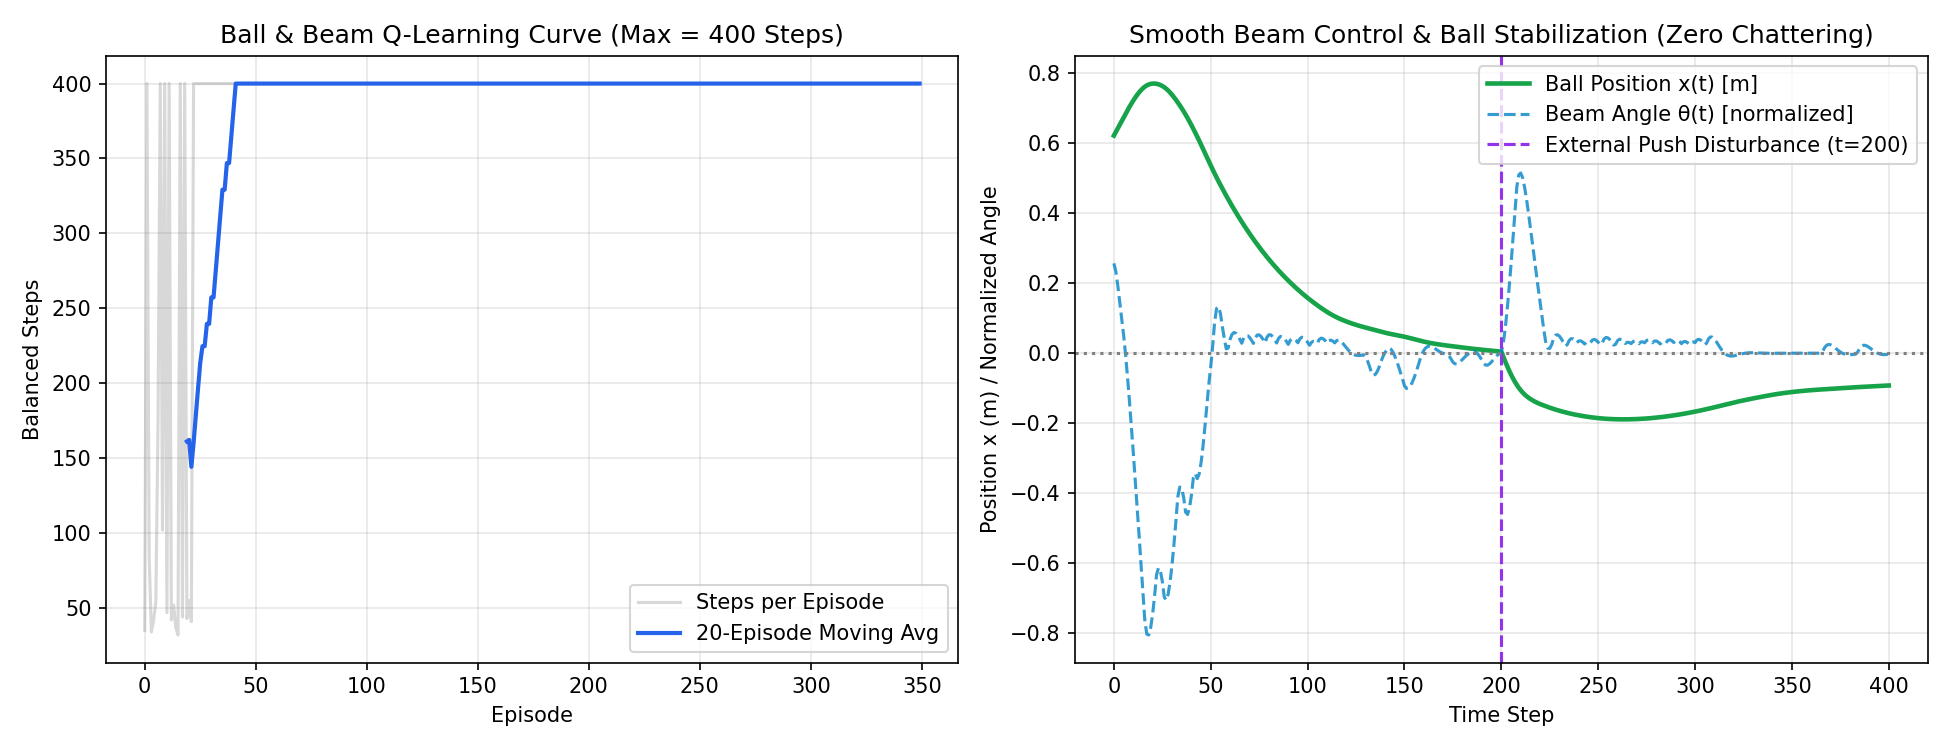

In [3]:
env = BallAndBeamEnv(seed=42)
agent = QLearningBallBeamAgent(env)
agent.train_episodes_fast(350)
print(f"Số bước giữ bóng trung bình (20 episodes đầu):  {np.mean(agent.steps_history[:20]):.1f} / 400 bước")
print(f"Số bước giữ bóng trung bình (20 episodes cuối): {np.mean(agent.steps_history[-20:]):.1f} / 400 bước")
